## Quantile Regression Example 1

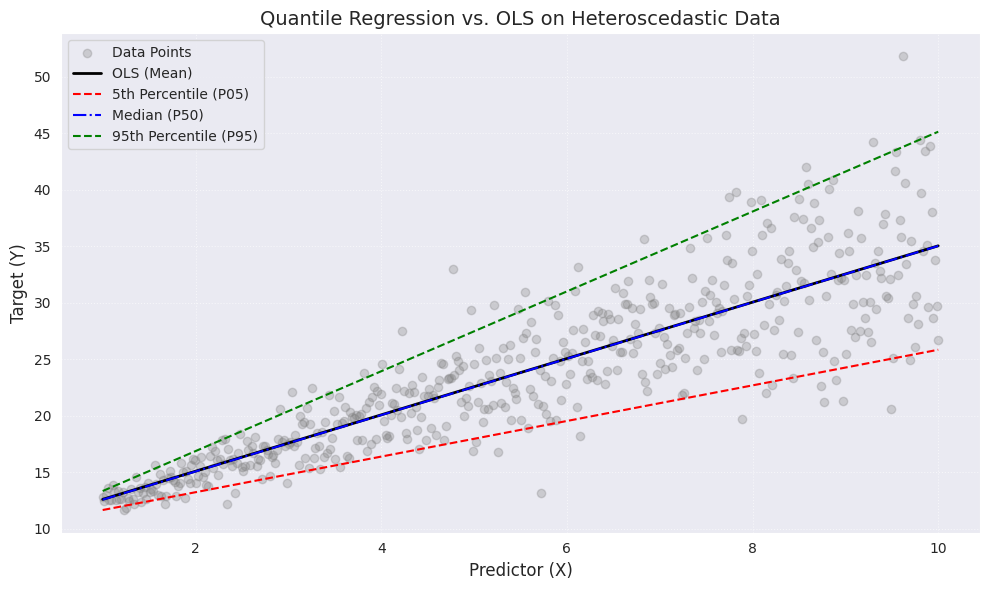


--- Model Coefficients Comparison ---
                 OLS  Quantile 0.05  Quantile 0.5  Quantile 0.95
Intercept  10.090627      10.065902     10.062833       9.790015
Slope       2.493696       1.576144      2.495533       3.533708


In [37]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# ==========================================
# 1. Generate Synthetic Heteroscedastic Data
# ==========================================
np.random.seed(42)
n = 500
x = np.linspace(1, 10, n)

# Notice how the error term is multiplied by x:
# As x grows, the variance (spread) fans out.
error = np.random.normal(0, 0.6 * x, n)
y = 2.5 * x + 10 + error

df = pd.DataFrame({"x": x, "y": y})

# ==========================================
# 2. Fit OLS (Ordinary Least Squares) Model
# ==========================================
ols_model = smf.ols("y ~ x", data=df).fit()
df["ols_pred"] = ols_model.predict(df["x"])

# ==========================================
# 3. Fit Quantile Regression Models
# ==========================================
# We want the median (0.50) and our 90% interval bounds (0.05 and 0.95)
quantiles = [0.05, 0.50, 0.95]
quantile_results = {}

for q in quantiles:
    mod = smf.quantreg("y ~ x", data=df)
    # Fit the model for the specific quantile tau (q)
    res = mod.fit(q=q)
    quantile_results[q] = res
    df[f"q_{int(q*100)}"] = res.predict(df["x"])

# ==========================================
# 4. Visualize the Results
# ==========================================
plt.figure(figsize=(10, 6))

# Scatter plot of raw data
plt.scatter(df["x"], df["y"], alpha=0.3, color="gray", label="Data Points")

# OLS Mean Line
plt.plot(df["x"], df["ols_pred"], color="black", linewidth=2, label="OLS (Mean)")

# Quantile Lines
plt.plot(df["x"], df["q_5"], color="red", linestyle="--", label="5th Percentile (P05)")
plt.plot(df["x"], df["q_50"], color="blue", linestyle="-.", label="Median (P50)")
plt.plot(df["x"], df["q_95"], color="green", linestyle="--", label="95th Percentile (P95)")

# Formatting the plot
plt.title("Quantile Regression vs. OLS on Heteroscedastic Data", fontsize=14)
plt.xlabel("Predictor (X)", fontsize=12)
plt.ylabel("Target (Y)", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# ==========================================
# 5. Inspecting Coefficients
# ==========================================
# Print a quick summary table comparing OLS coefficients to Quantile coefficients
summary_data = {
    "OLS": [ols_model.params["Intercept"], ols_model.params["x"]],
}
for q in quantiles:
    summary_data[f"Quantile {q}"] = [
        quantile_results[q].params["Intercept"],
        quantile_results[q].params["x"],
    ]

summary_df = pd.DataFrame(summary_data, index=["Intercept", "Slope"])
print("\n--- Model Coefficients Comparison ---")
print(summary_df.to_string())

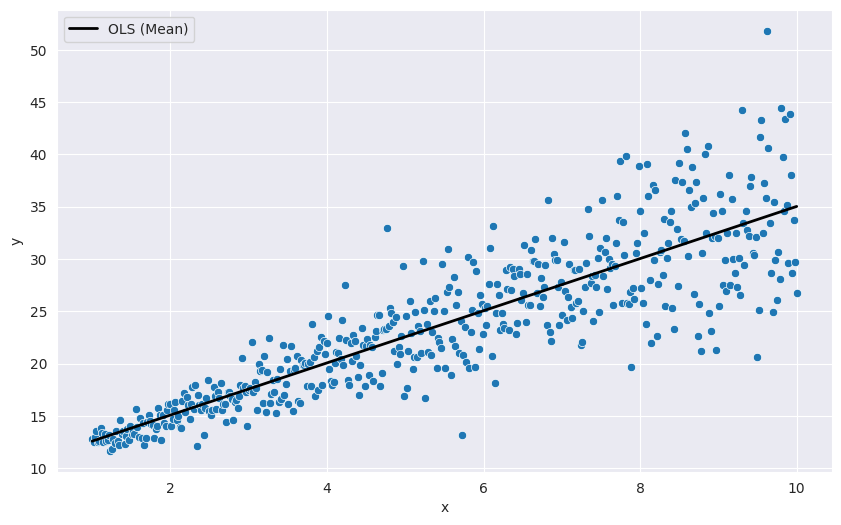

In [43]:
plt.figure(figsize=(10, 6))
plt.plot(df["x"], df["ols_pred"], color="black", linewidth=2, label="OLS (Mean)")
sns.scatterplot(data=df, x='x', y='y')
plt.show()

# Quantile Regression witb House Prices Dataset

## Imports

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

## Data Load

In [56]:
# Load datset
df = pd.read_csv('/content/hprice1.csv')
df.sample(3)

,price,assess,bdrms,lotsize,sqrft,colonial,lprice,lassess,llotsize,lsqrft
56,209.000000,230.699997,4,5600,1674,1,5.342334,5.441118,8.630522,7.422971
30,230.000000,217.800003,4,4806,1573,1,5.438079,5.383577,8.477620,7.360740
15,227.399994,232.899994,4,3597,1760,1,5.426711,5.450609,8.187856,7.473069


In [57]:
# Check data types and NAs
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   price     88 non-null     float64
 1   assess    88 non-null     float64
 2   bdrms     88 non-null     int64  
 3   lotsize   88 non-null     int64  
 4   sqrft     88 non-null     int64  
 5   colonial  88 non-null     int64  
 6   lprice    88 non-null     float64
 7   lassess   88 non-null     float64
 8   llotsize  88 non-null     float64
 9   lsqrft    88 non-null     float64
dtypes: float64(6), int64(4)
memory usage: 7.0 KB


## Quick Data Exploratory Analysis

In [4]:
# Let's describe the data
df.describe()

,price,assess,bdrms,lotsize,sqrft,colonial,lprice,lassess,llotsize,lsqrft
count,88.000000,88.000000,88.000000,88.000000,88.000000,88.000000,88.000000,88.000000,88.000000,88.000000
mean,293.546034,315.736362,3.568182,9019.863636,2013.693182,0.693182,5.633180,5.717994,8.905104,7.572610
std,102.713445,95.314435,0.841393,10174.150414,577.191583,0.463816,0.303573,0.262113,0.544060,0.258688
min,111.000000,198.699997,2.000000,1000.000000,1171.000000,0.000000,4.709530,5.291796,6.907755,7.065613
25%,230.000000,253.900002,3.000000,5732.750000,1660.500000,0.000000,5.438079,5.536940,8.653908,7.414873
50%,265.500000,290.199997,3.000000,6430.000000,1845.000000,1.000000,5.581613,5.670567,8.768719,7.520231
75%,326.250000,352.125000,4.000000,8583.250000,2227.000000,1.000000,5.787642,5.863982,9.057567,7.708266
max,725.000000,708.599976,7.000000,92681.000000,3880.000000,1.000000,6.586172,6.563291,11.436919,8.263591


* The descriptive stats show that there are no discrepant values or apparently erroneous, such as 9999
* Price (TARGET) has a std of 102, while the mean is 293, so approx. 1/3 of the price avg.
* The data is right skewed, pulling the avg higher

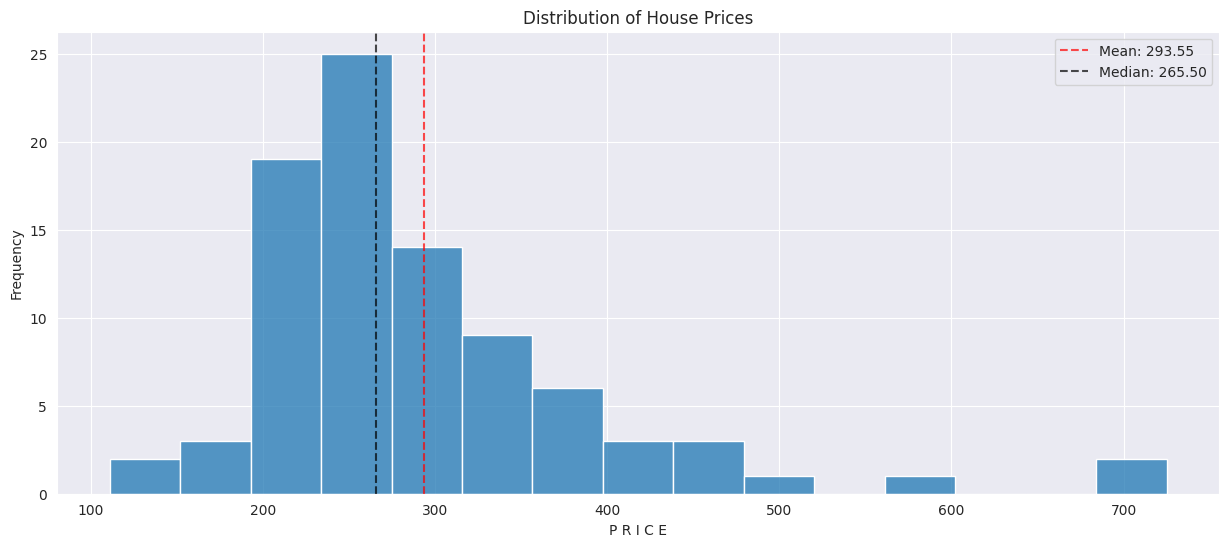

In [5]:
# Looking at the target variable distribution with a mean line
plt.figure(figsize=(15, 6))
sns.histplot(df['price'])
plt.axvline(x=df['price'].mean(), color='red', linestyle='--', alpha=0.7, label=f"Mean: {df['price'].mean():.2f}")
plt.axvline(x=df['price'].median(), color='black', linestyle='--', alpha=0.7, label=f"Median: {df['price'].median():.2f}")
plt.legend()
plt.title('Distribution of House Prices')
plt.xlabel('P R I C E')
plt.ylabel('Frequency')
plt.show()

* Good correlations of the predictor variables with the Target. Only `lotsize` and `colonial` are weak.
* `sqrft` and `lsqrft` are colinear. We should drop one of them.
* `assess` and `lassess` are colinear. We should drop one of them.

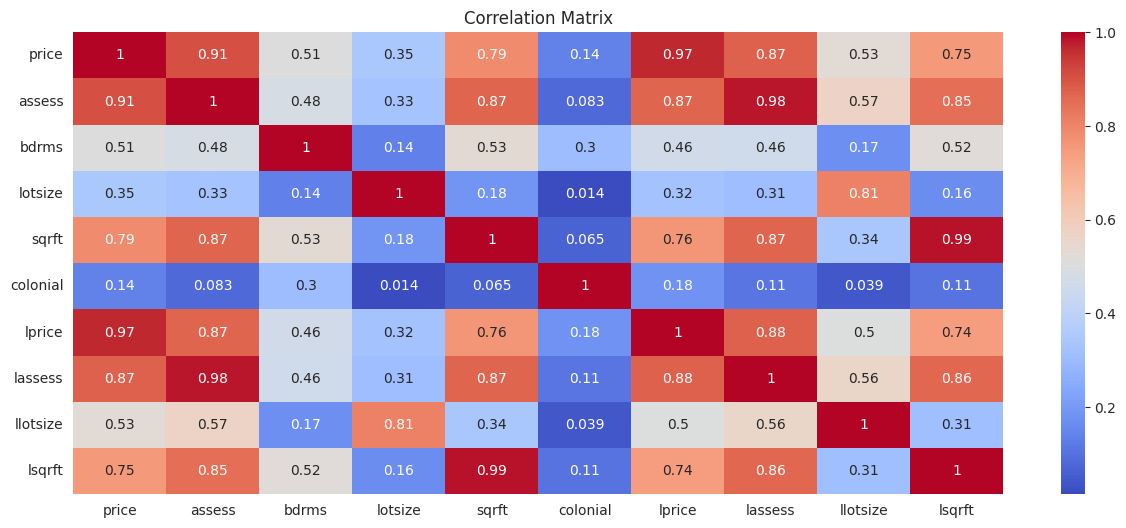

In [6]:
* # Correlation
plt.figure(figsize=(15, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

## OLS Regression

In [20]:
# OLS Regression with Statsmodels
ols_model = smf.ols("price ~ bdrms + lotsize +  assess", data=df)
ols_results = ols_model.fit()
print(ols_results.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.829
Model:                            OLS   Adj. R-squared:                  0.823
Method:                 Least Squares   F-statistic:                     135.9
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           3.91e-32
Time:                        22:57:46   Log-Likelihood:                -454.21
No. Observations:                  88   AIC:                             916.4
Df Residuals:                      84   BIC:                             926.3
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -38.9514     21.265     -1.832      0.0

In [19]:
# ==========================================
# Fit Quantile Regression Models (Q10, Q50, Q90)
# ==========================================
quantiles = [0.10, 0.50, 0.90]
quantile_results = {}

# We will use the same formula as your OLS model
formula = "price ~ bdrms + lotsize + assess + sqrft"

# Fit the model for each quantile with increased max_iter
for q in quantiles:
    mod = smf.quantreg(formula, data=df)
    res = mod.fit(q=q, max_iter=5000)
    quantile_results[q] = res

# Compare coefficients between OLS and different Quantiles
summary_data = {
    "OLS": ols_results.params
}
for q in quantiles:
    summary_data[f"Quantile {q:.2f}"] = quantile_results[q].params

comparison_df = pd.DataFrame(summary_data)
print("--- Coefficients Comparison across Quantiles and OLS ---")
display(comparison_df)

--- Coefficients Comparison across Quantiles and OLS ---


,OLS,Quantile 0.10,Quantile 0.50,Quantile 0.90
Intercept,-1634.773602,31.159182,0.830147,-44.435178
assess,NaN,0.654216,0.892141,1.027086
bdrms,8.785496,-6.605016,3.320612,15.711347
lassess,17.205041,NaN,NaN,NaN
llotsize,11.572973,NaN,NaN,NaN
lotsize,-0.000044,0.001148,0.000508,-0.000087
lprice,285.347450,NaN,NaN,NaN
lsqrft,11.689502,NaN,NaN,NaN
sqrft,NaN,0.008084,-0.003850,0.002603


## Quantile Regression

In [58]:
# ==========================================
# Fit a Simplified Quantile Regression Model
# ==========================================
# Dropping highly collinear and target-derived variables (lprice, lassess)
clean_formula = "price ~ bdrms + lotsize + sqrft"

# Re-fitting OLS with this simplified formula for reference
simplified_ols = smf.ols(clean_formula, data=df).fit()

quantiles = [0.05, 0.50, 0.95]
simplified_results = {}

for q in quantiles:
    mod = smf.quantreg(clean_formula, data=df)
    res = mod.fit(q=q)
    simplified_results[q] = res

# Create a comparison dataframe of coefficients
simplified_summary = {
    "OLS": simplified_ols.params
}
for q in quantiles:
    simplified_summary[f"Quantile {q:.2f}"] = simplified_results[q].params

simplified_comp_df = pd.DataFrame(simplified_summary)
print("--- Simplified Model Coefficients Comparison ---")
display(simplified_comp_df)

--- Simplified Model Coefficients Comparison ---


,OLS,Quantile 0.05,Quantile 0.50,Quantile 0.95
Intercept,-21.770308,0.000058,10.699794,7.284112
bdrms,13.852522,0.000230,14.690035,19.224097
lotsize,0.002068,0.001460,0.002492,0.009580
sqrft,0.122778,0.107695,0.097205,0.101964


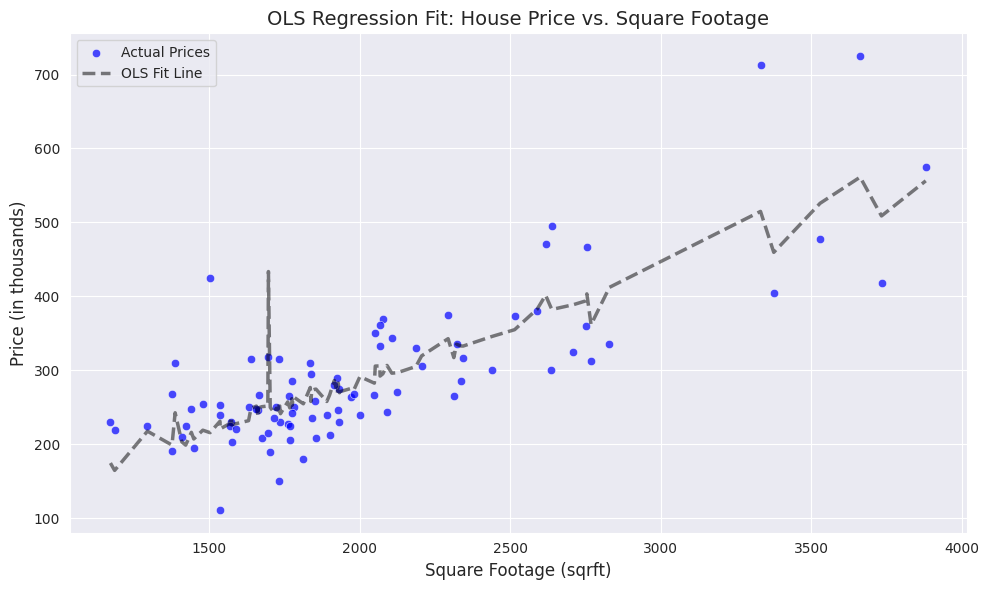

In [59]:
from matplotlib.lines import lineStyles
# Predict using the simplified OLS model to get the fitted line values
df['ols_preds'] = simplified_ols.predict(df)

# Sort by sqrft so that the plotting line connects correctly
plot_df = df.sort_values(by='sqrft')

# Scatterplot of actual prices vs. sqrft with the OLS line overlaid
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='sqrft', y='price', color='blue', alpha=0.7, label='Actual Prices')
plt.plot(plot_df['sqrft'], plot_df['ols_preds'], color='black', linewidth=2.5, linestyle='--', alpha=0.5, label='OLS Fit Line')

plt.title('OLS Regression Fit: House Price vs. Square Footage', fontsize=14)
plt.xlabel('Square Footage (sqrft)', fontsize=12)
plt.ylabel('Price (in thousands)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

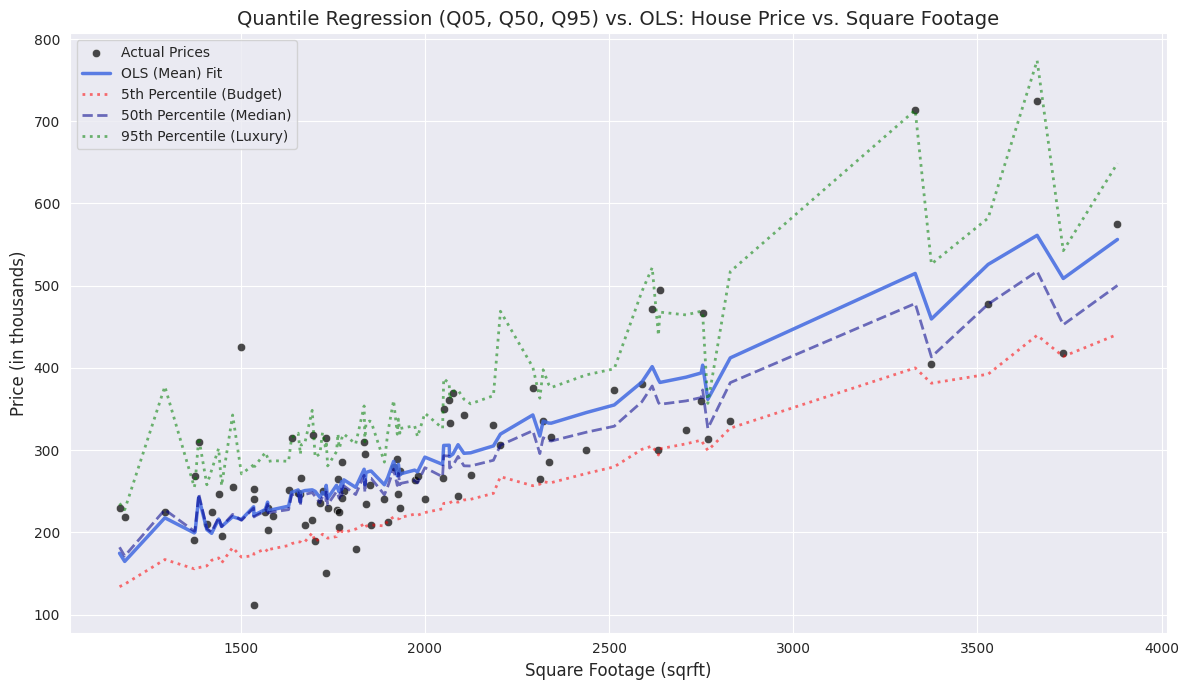

In [69]:
# Generate predictions for each of our simplified quantile models
for q in quantiles:
    df[f'q_{int(q*100)}_preds'] = simplified_results[q].predict(df)

# Sort by sqrft so that the plotting lines connect smoothly
plot_df_sorted = df.sort_values(by='sqrft')
plot_df_sorted = plot_df_sorted.query('q_95_preds < 1140')

plt.figure(figsize=(12, 7))

# Scatterplot of actual prices vs. sqrft
sns.scatterplot(data=df, x='sqrft', y='price', color='black', alpha=0.7, label='Actual Prices')

# Plot the OLS model prediction line
plt.plot(plot_df_sorted['sqrft'], plot_df_sorted['ols_preds'], color='royalblue', linewidth=2.5, linestyle='-', label='OLS (Mean) Fit', alpha=0.85)

# Plot the Quantile prediction lines
plt.plot(plot_df_sorted['sqrft'], plot_df_sorted['q_5_preds'], color='red', linewidth=2, linestyle=':', label='5th Percentile (Budget)', alpha=0.55)
plt.plot(plot_df_sorted['sqrft'], plot_df_sorted['q_50_preds'], color='darkblue', linewidth=2, linestyle='--', label='50th Percentile (Median)', alpha=0.55)
plt.plot(plot_df_sorted['sqrft'], plot_df_sorted['q_95_preds'], color='green', linewidth=2, linestyle=':', label='95th Percentile (Luxury)', alpha=0.55)

plt.title('Quantile Regression (Q05, Q50, Q95) vs. OLS: House Price vs. Square Footage', fontsize=14)
plt.xlabel('Square Footage (sqrft)', fontsize=12)
plt.ylabel('Price (in thousands)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

In [62]:
df.sort_values(by='q_95_preds', ascending=False)

,price,assess,bdrms,lotsize,sqrft,colonial,lprice,lassess,llotsize,lsqrft,ols_preds,q_5_preds,q_50_preds,q_95_preds
76,318.0,295.200012,4,92681,1696,1,5.762052,5.687653,11.436919,7.436028,433.508697,318.000000,465.271048,1145.000999
72,725.0,708.599976,5,31000,3662,0,6.586172,6.563291,10.341743,8.205765,561.204919,439.652135,517.364918,773.777135
41,713.5,655.400024,5,28231,3331,1,6.570182,6.485246,10.248176,8.111028,514.839861,399.961292,478.289871,713.500000
37,575.0,518.099976,5,15634,3880,1,6.354370,6.250168,9.657204,8.263591,556.198184,440.689714,500.265366,648.797841
28,477.5,478.100006,7,8400,3529,1,6.168564,6.169820,9.035987,8.168770,525.850295,392.324900,477.500000,582.154622
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52,210.0,198.699997,3,5146,1408,1,5.347107,5.291796,8.545975,7.249926,203.299360,159.150549,204.458455,257.820070
3,195.0,231.800003,3,4600,1448,1,5.273000,5.445875,8.433811,7.277938,207.081520,162.660996,206.986103,256.667893
2,191.0,217.699997,3,5200,1374,0,5.252274,5.383118,8.556414,7.225482,199.236558,155.567774,201.288031,254.870634
43,230.0,212.100006,3,5305,1171,0,5.438079,5.357058,8.576406,7.065613,174.529695,133.858998,181.816969,235.177947
